## 1. Environment and configuration

The assignment's effective SFT batch size remains 16 and reward-model effective batch size remains 8. To reduce activation memory on a Kaggle T4, training uses smaller micro-batches with gradient accumulation.

In [13]:
import os
import gc
import json
import math
import time
import random
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

In [14]:
SEED = 42

MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"
SFT_DATASET_NAME = "CarperAI/openai_summarize_tldr"
PREFERENCE_DATASET_NAME = "CarperAI/openai_summarize_comparisons"

MAX_PROMPT_TOKENS = 448
MAX_SUMMARY_TOKENS = 48

SFT_TRAIN_SIZE = 20_000
SFT_VALID_SIZE = 500
PREFERENCE_TRAIN_SIZE = 20_000
PREFERENCE_VALID_SIZE = 1_000
EVAL_POSTS_SIZE = 300

# Micro-batches + accumulation preserve the required effective batch sizes.
SFT_EFFECTIVE_BATCH_SIZE = 16
SFT_MICRO_BATCH_SIZE = 2
SFT_GRAD_ACCUM_STEPS = SFT_EFFECTIVE_BATCH_SIZE // SFT_MICRO_BATCH_SIZE

RM_EFFECTIVE_BATCH_SIZE = 8
RM_MICRO_BATCH_SIZE = 1  # one preference pair; forward pass contains chosen + rejected
RM_GRAD_ACCUM_STEPS = RM_EFFECTIVE_BATCH_SIZE // RM_MICRO_BATCH_SIZE

SFT_EPOCHS = 1
SFT_LEARNING_RATE = 5e-5
SFT_WEIGHT_DECAY = 0.01
SFT_MAX_GRAD_NORM = 1.0
SFT_LOG_INTERVAL = 250

RM_EPOCHS = 1
RM_LEARNING_RATE = 1e-5
RM_MAX_GRAD_NORM = 1.0
RM_LOG_INTERVAL = 250

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Kaggle's writable output directory; falls back to current directory elsewhere.
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
CHECKPOINT_ROOT = WORK_DIR / "checkpoints"
SFT_CHECKPOINT_DIR = CHECKPOINT_ROOT / "sft"
RM_CHECKPOINT_DIR = CHECKPOINT_ROOT / "reward"
RESULTS_DIR = WORK_DIR / "results"

for directory in (SFT_CHECKPOINT_DIR, RM_CHECKPOINT_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Working directory:", WORK_DIR)
print("SFT effective/micro batch:",
      SFT_EFFECTIVE_BATCH_SIZE, "/", SFT_MICRO_BATCH_SIZE)
print("Reward effective/micro batch:",
      RM_EFFECTIVE_BATCH_SIZE, "/", RM_MICRO_BATCH_SIZE)

Device: cuda
GPU: Tesla T4
Working directory: /kaggle/working
SFT effective/micro batch: 16 / 2
Reward effective/micro batch: 8 / 1


In [15]:
# Extra configuration for Stages 3-4 and evaluation.
PPO_CHECKPOINT_DIR = CHECKPOINT_ROOT / "ppo"
DPO_CHECKPOINT_DIR = CHECKPOINT_ROOT / "dpo"
for directory in (PPO_CHECKPOINT_DIR, DPO_CHECKPOINT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

STAGE_TIME = {}   # seconds per stage, filled in as each stage finishes (needed for Table 2)

## 2. Tokenizer and data utilities

The source datasets use `prompt`/`label` for SFT and `prompt`/`chosen`/`rejected` for preference training. Prompts are normalized to end in `TL;DR:`. Summaries have any leading `TL;DR:` and trailing `<|endoftext|>` removed.

Padding masks are built from sequence lengths, not token IDs, because the tokenizer's PAD token is EOS.

In [16]:
TLDR_MARKER = "TL;DR:"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

if tokenizer.eos_token_id is None or tokenizer.pad_token_id is None:
    raise ValueError("Tokenizer must have valid EOS and PAD token IDs.")

PAD_ID = tokenizer.pad_token_id
EOS_ID = tokenizer.eos_token_id

def clean_post(raw_prompt: str) -> str:
    if not isinstance(raw_prompt, str):
        raise TypeError("Prompt must be a string.")
    text = raw_prompt.split(TLDR_MARKER)[0].strip()
    return text + "\n" + TLDR_MARKER

def clean_summary(raw_summary: str) -> str:
    if not isinstance(raw_summary, str):
        raise TypeError("Summary must be a string.")
    text = raw_summary.split("<|endoftext|>")[0].strip()
    if text.startswith(TLDR_MARKER):
        text = text[len(TLDR_MARKER):].strip()
    return " " + text

def token_ids(text: str):
    return tokenizer(text, add_special_tokens=False)["input_ids"]

def sample_valid_rows(split, count, builder, seed=SEED):
    indices = list(range(len(split)))
    random.Random(seed).shuffle(indices)
    selected = []
    for idx in indices:
        item = builder(split[idx])
        if item is not None:
            selected.append(item)
            if len(selected) == count:
                break
    if len(selected) != count:
        raise ValueError(
            f"Only found {len(selected)} valid examples; required {count}. "
            "Check dataset fields and token limits."
        )
    return selected

## 3. Load datasets and create fixed subsets

In [17]:
sft_dataset = load_dataset(SFT_DATASET_NAME)
preference_dataset = load_dataset(PREFERENCE_DATASET_NAME)

print("SFT splits:", {k: len(v) for k, v in sft_dataset.items()})
print("SFT columns:", sft_dataset["train"].column_names)
print("Preference splits:", {k: len(v) for k, v in preference_dataset.items()})
print("Preference columns:", preference_dataset["train"].column_names)

required_sft = {"prompt", "label"}
required_pref = {"prompt", "chosen", "rejected"}

for split_name in ("train", "valid", "test"):
    missing = required_sft.difference(sft_dataset[split_name].column_names)
    if missing:
        raise KeyError(f"SFT {split_name} missing columns: {sorted(missing)}")

for split_name in ("train", "valid1"):
    missing = required_pref.difference(preference_dataset[split_name].column_names)
    if missing:
        raise KeyError(f"Preference {split_name} missing columns: {sorted(missing)}")

SFT splits: {'train': 116722, 'test': 6553, 'valid': 6447}
SFT columns: ['prompt', 'label']
Preference splits: {'train': 92534, 'test': 83629, 'valid1': 33082, 'valid2': 50715}
Preference columns: ['prompt', 'chosen', 'rejected']


In [18]:
def build_sft_record(row):
    prompt = clean_post(row["prompt"])
    summary = clean_summary(row["label"])
    prompt_ids = token_ids(prompt)
    summary_ids = token_ids(summary) + [EOS_ID]

    if not summary.strip() or len(prompt_ids) > MAX_PROMPT_TOKENS:
        return None
    if len(summary_ids) > MAX_SUMMARY_TOKENS:
        return None

    input_ids = prompt_ids + summary_ids
    labels = [-100] * len(prompt_ids) + summary_ids

    return {
        "prompt": prompt,
        "summary": summary.strip(),
        "prompt_ids": prompt_ids,
        "summary_ids": summary_ids,
        "input_ids": input_ids,
        "labels": labels,
        "prompt_length": len(prompt_ids),
        "target_length": len(summary_ids),
    }

def build_preference_record(row):
    prompt = clean_post(row["prompt"])
    chosen = clean_summary(row["chosen"])
    rejected = clean_summary(row["rejected"])

    if not chosen.strip() or not rejected.strip() or chosen.strip() == rejected.strip():
        return None

    prompt_ids = token_ids(prompt)
    chosen_ids = token_ids(chosen) + [EOS_ID]
    rejected_ids = token_ids(rejected) + [EOS_ID]

    if len(prompt_ids) > MAX_PROMPT_TOKENS:
        return None
    if max(len(chosen_ids), len(rejected_ids)) > MAX_SUMMARY_TOKENS:
        return None

    return {
        "prompt": prompt,
        "prompt_ids": prompt_ids,
        "chosen": chosen.strip(),
        "rejected": rejected.strip(),
        "chosen_ids": prompt_ids + chosen_ids,
        "rejected_ids": prompt_ids + rejected_ids,
    }

sft_train_records = sample_valid_rows(
    sft_dataset["train"], SFT_TRAIN_SIZE, build_sft_record
)
sft_valid_records = sample_valid_rows(
    sft_dataset["valid"], SFT_VALID_SIZE, build_sft_record
)
preference_train_records = sample_valid_rows(
    preference_dataset["train"], PREFERENCE_TRAIN_SIZE, build_preference_record
)
preference_valid_records = sample_valid_rows(
    preference_dataset["valid1"], PREFERENCE_VALID_SIZE, build_preference_record
)
eval_records = sample_valid_rows(
    sft_dataset["test"], EVAL_POSTS_SIZE, build_sft_record
)

print("SFT train/validation:", len(sft_train_records), len(sft_valid_records))
print("Preference train/validation:",
      len(preference_train_records), len(preference_valid_records))
print("Held-out evaluation posts:", len(eval_records))
print("SFT example keys:", sft_train_records[0].keys())
print("Preference example keys:", preference_train_records[0].keys())

SFT train/validation: 20000 500
Preference train/validation: 20000 1000
Held-out evaluation posts: 300
SFT example keys: dict_keys(['prompt', 'summary', 'prompt_ids', 'summary_ids', 'input_ids', 'labels', 'prompt_length', 'target_length'])
Preference example keys: dict_keys(['prompt', 'prompt_ids', 'chosen', 'rejected', 'chosen_ids', 'rejected_ids'])


In [19]:
def autocast_context():
    if DEVICE.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()

scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

def enable_gradient_checkpointing(model):
    model.config.use_cache = False
    try:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    except TypeError:
        model.gradient_checkpointing_enable()
    return model

def freeze(model):
    model.eval()
    for p in model.parameters():
        p.requires_grad = False
    assert all(not p.requires_grad for p in model.parameters())
    return model

def free_memory():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

def save_json(path, payload):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, ensure_ascii=False, indent=2)

def make_position_ids(attention_mask):
    """Position of each real token among the real tokens (works for left AND right padding)."""
    return (attention_mask.cumsum(-1) - 1).clamp(min=0)

def left_pad(seqs):
    """Left-padded (ids, mask) on DEVICE, for model.generate and PPO rollouts."""
    L = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), L), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, L - len(s):] = torch.tensor(s, dtype=torch.long)
        mask[i, L - len(s):] = 1
    return ids.to(DEVICE), mask.to(DEVICE)

def chunk_slices(n, parts):
    size = math.ceil(n / parts)
    return [slice(i, min(i + size, n)) for i in range(0, n, size)]

def pad_sequences(sequences, pad_id=PAD_ID):
    """Right padding. Mask is built from lengths, never from token ids (PAD == EOS here)."""
    max_len = max(len(s) for s in sequences)
    input_ids = torch.full((len(sequences), max_len), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(sequences), max_len), dtype=torch.long)
    for i, seq in enumerate(sequences):
        input_ids[i, :len(seq)] = torch.tensor(seq, dtype=torch.long)
        attention_mask[i, :len(seq)] = 1
    return input_ids, attention_mask

/tmp/ipykernel_50/2211671561.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))


## Task 1 — Data statistics and the helper used in every stage

`token_logprobs(model, input_ids, attention_mask)` returns `log π(x_t | x_<t)` for `t = 1 … L-1`, shape `(B, L-1)`.
`summary_mask(attention_mask, prompt_lens)` is 1 exactly on summary tokens (not prompt, not padding), same shape.
Both assume **right-padded** sequences (SFT / preference / DPO / reward data).

In [20]:
# ---- Table 1: data statistics ----
p_lens = [r["prompt_length"] for r in sft_train_records]
s_lens = [r["target_length"] for r in sft_train_records]   # includes the EOS token
table1 = {
    "sft_train": len(sft_train_records), "sft_val": len(sft_valid_records),
    "pref_train": len(preference_train_records), "pref_val": len(preference_valid_records),
    "eval_posts": len(eval_records),
    "prompt_len_mean": float(np.mean(p_lens)), "prompt_len_max": int(np.max(p_lens)),
    "summary_len_mean": float(np.mean(s_lens)), "summary_len_max": int(np.max(s_lens)),
}
print(json.dumps(table1, indent=2))
save_json(RESULTS_DIR / "table1_data.json", table1)

# ---- Task 1.3 helpers ----
def token_logprobs(model, input_ids, attention_mask):
    """log pi(x_t | x_<t) for t = 1..L-1  ->  (B, L-1). Gradients flow if the model is in grad mode."""
    with autocast_context():
        logits = model(input_ids=input_ids, attention_mask=attention_mask,
                       position_ids=make_position_ids(attention_mask), use_cache=False).logits
    logits = logits[:, :-1].float()
    target = logits.gather(-1, input_ids[:, 1:].unsqueeze(-1)).squeeze(-1)
    return target - torch.logsumexp(logits, dim=-1)

def summary_mask(attention_mask, prompt_lens):
    """(B, L-1) mask, 1 on positions whose *target* token t is a summary token.
    Target index t (1..L-1) is a summary token iff t >= prompt_len and it is a real (non-pad) token."""
    L = attention_mask.shape[1]
    t = torch.arange(1, L, device=attention_mask.device).unsqueeze(0)
    pl = prompt_lens.to(attention_mask.device).unsqueeze(1)
    return ((t >= pl) & attention_mask[:, 1:].bool()).long()

# ---- Check: mask selects exactly summary + EOS (no model needed) ----
demo = sft_train_records[:5]
ids, am = pad_sequences([r["input_ids"] for r in demo])
pl = torch.tensor([r["prompt_length"] for r in demo])
m = summary_mask(am, pl)
for r, i_row, m_row in zip(demo, ids, m):
    decoded = tokenizer.decode(i_row[1:][m_row.bool()])
    expected = " " + r["summary"] + tokenizer.eos_token
    assert decoded == expected, (decoded, expected)
print("SFT mask check passed. Example decoded summary tokens:")
print(repr(tokenizer.decode(ids[0, 1:][m[0].bool()])))

{
  "sft_train": 20000,
  "sft_val": 500,
  "pref_train": 20000,
  "pref_val": 1000,
  "eval_posts": 300,
  "prompt_len_mean": 317.41865,
  "prompt_len_max": 448,
  "summary_len_mean": 33.8159,
  "summary_len_max": 48
}
SFT mask check passed. Example decoded summary tokens:
' Me and my sister were going to the park, put my sister in her carseat, left her there for thirty minutes, mom saved her from my ignorance, got grounded for a month.<|endoftext|>'


## 4. Collators and DataLoaders

SFT: one DataLoader batch = 16 sequences (effective batch). It is split into micro-batches of 2 inside the training loop, so the loss is the mean over **all summary tokens of the 16-sequence batch**.
Reward / DPO: one item = one preference pair; chosen and rejected sequences are stacked in one forward pass (`pair_count` chosen first, then `pair_count` rejected).

In [21]:
def collate_sft(features):
    input_ids, attention_mask = pad_sequences([x["input_ids"] for x in features])
    prompt_lens = torch.tensor([x["prompt_length"] for x in features])
    return {"input_ids": input_ids, "attention_mask": attention_mask, "prompt_lens": prompt_lens}

def collate_reward(features):
    n = len(features)
    seqs = [x["chosen_ids"] for x in features] + [x["rejected_ids"] for x in features]
    input_ids, attention_mask = pad_sequences(seqs)
    prompt_lens = torch.tensor([len(x["prompt_ids"]) for x in features] * 2)
    return {"input_ids": input_ids, "attention_mask": attention_mask,
            "prompt_lens": prompt_lens, "pair_count": n}

_g = torch.Generator().manual_seed(SEED)
sft_train_loader = DataLoader(sft_train_records, batch_size=SFT_EFFECTIVE_BATCH_SIZE, shuffle=True,
                              collate_fn=collate_sft, generator=_g)
sft_valid_loader = DataLoader(sft_valid_records, batch_size=8, shuffle=False, collate_fn=collate_sft)
rm_train_loader = DataLoader(preference_train_records, batch_size=RM_MICRO_BATCH_SIZE, shuffle=True,
                             collate_fn=collate_reward, generator=torch.Generator().manual_seed(SEED))
rm_valid_loader = DataLoader(preference_valid_records, batch_size=16, shuffle=False, collate_fn=collate_reward)

print("SFT optimizer steps per epoch:", len(sft_train_loader))
print("Reward micro-batches per epoch:", len(rm_train_loader), "->", len(rm_train_loader) // RM_GRAD_ACCUM_STEPS, "optimizer steps")

SFT optimizer steps per epoch: 1250
Reward micro-batches per epoch: 20000 -> 2500 optimizer steps


## 6. Stage 1 — Supervised fine-tuning

Loss (written here, not taken from `outputs.loss`): `L = - Σ_{t ∈ summary} log π(x_t | x_<t) / #summary tokens`, where the token count is over the whole 16-sequence batch. AdamW, lr 5e-5, batch 16 (2 × 8 accumulation), clip 1.0. Training and validation loss are logged every 250 optimizer steps.

In [22]:
sft_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype=torch.float32)
sft_model.config.pad_token_id = PAD_ID
sft_model = enable_gradient_checkpointing(sft_model).to(DEVICE)
assert next(sft_model.parameters()).dtype == torch.float32

sft_optimizer = torch.optim.AdamW(sft_model.parameters(), lr=SFT_LEARNING_RATE, weight_decay=SFT_WEIGHT_DECAY)
print("SFT parameters:", sum(p.numel() for p in sft_model.parameters()))

# Task 1.3 shape check of the helper on a real batch
_b = next(iter(sft_valid_loader))
_ids, _am, _pl = (_b[k].to(DEVICE) for k in ("input_ids", "attention_mask", "prompt_lens"))
with torch.no_grad():
    _lp = token_logprobs(sft_model, _ids, _am)
_m = summary_mask(_am, _pl)
assert _lp.shape == (_ids.size(0), _ids.size(1) - 1) == _m.shape
print("token_logprobs / summary_mask shapes OK:", tuple(_lp.shape))
del _b, _ids, _am, _pl, _lp, _m

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

SFT parameters: 134515008
token_logprobs / summary_mask shapes OK: (8, 469)


In [23]:
@torch.no_grad()
def sft_validation_loss(model, loader):
    was_training = model.training
    model.eval()
    total, count = 0.0, 0.0
    for b in loader:
        ids, am, pl = (b[k].to(DEVICE) for k in ("input_ids", "attention_mask", "prompt_lens"))
        lp = token_logprobs(model, ids, am)
        m = summary_mask(am, pl).float()
        total += -(lp * m).sum().item()
        count += m.sum().item()
    model.train(was_training)
    return total / count

def train_sft(model, train_loader, valid_loader, optimizer):
    hist = {"step": [], "train_loss": [], "val_loss": []}
    run_loss, run_steps = 0.0, 0
    model.train()
    start = time.time()
    for step, b in enumerate(train_loader, start=1):
        ids, am, pl = (b[k].to(DEVICE) for k in ("input_ids", "attention_mask", "prompt_lens"))
        full_mask = summary_mask(am, pl).float()          # (16, L-1)
        n_tokens = full_mask.sum()                        # summary tokens in the whole 16-sequence batch
        optimizer.zero_grad(set_to_none=True)
        step_loss = 0.0
        for s in range(0, ids.size(0), SFT_MICRO_BATCH_SIZE):
            sl = slice(s, s + SFT_MICRO_BATCH_SIZE)
            Lm = int(am[sl].sum(1).max())                 # trim padding of this micro-batch
            lp = token_logprobs(model, ids[sl, :Lm], am[sl, :Lm])
            loss = -(lp * full_mask[sl, :Lm - 1]).sum() / n_tokens
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), SFT_MAX_GRAD_NORM)
        scaler.step(optimizer)
        scaler.update()
        run_loss += step_loss
        run_steps += 1
        if step % SFT_LOG_INTERVAL == 0 or step == len(train_loader):
            val = sft_validation_loss(model, valid_loader)
            hist["step"].append(step)
            hist["train_loss"].append(run_loss / run_steps)
            hist["val_loss"].append(val)
            print(f"SFT step {step:5d} | train loss {run_loss / run_steps:.4f} | val loss {val:.4f}")
            run_loss, run_steps = 0.0, 0
    return hist, time.time() - start

sft_history, STAGE_TIME["sft"] = train_sft(sft_model, sft_train_loader, sft_valid_loader, sft_optimizer)
print(f"SFT time: {STAGE_TIME['sft'] / 60:.1f} min")

SFT step   250 | train loss 2.4499 | val loss 2.4138
SFT step   500 | train loss 2.3915 | val loss 2.3885
SFT step   750 | train loss 2.3500 | val loss 2.3713
SFT step  1000 | train loss 2.3627 | val loss 2.3600
SFT step  1250 | train loss 2.3391 | val loss 2.3506
SFT time: 40.3 min


In [24]:
sft_model.config.use_cache = True
sft_model.save_pretrained(SFT_CHECKPOINT_DIR, safe_serialization=True)
tokenizer.save_pretrained(SFT_CHECKPOINT_DIR)
torch.save({"history": sft_history, "seconds": STAGE_TIME["sft"], "seed": SEED}, SFT_CHECKPOINT_DIR / "training_state.pt")
for f in ("config.json", "model.safetensors"):
    assert (SFT_CHECKPOINT_DIR / f).exists(), f
print("SFT checkpoint saved:", sorted(p.name for p in SFT_CHECKPOINT_DIR.iterdir()))
del sft_optimizer
free_memory()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

SFT checkpoint saved: ['config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_state.pt']


## 7. SFT generation sanity check

Generate from the original base model before fine-tuning and from the fine-tuned model after training. These are qualitative samples, not a substitute for the final 300-post evaluation.

In [25]:
def generate_summary(model, prompt, max_new_tokens=MAX_SUMMARY_TOKENS):
    model.eval()
    formatted_prompt = clean_post(prompt)
    encoded = tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_PROMPT_TOKENS,
        add_special_tokens=False,
    )
    encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
    with torch.inference_mode():
        with autocast_context():
            generated = model.generate(
                **encoded,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                num_beams=1,
                pad_token_id=PAD_ID,
                eos_token_id=EOS_ID,
                use_cache=True,
            )
    continuation = generated[0, encoded["input_ids"].shape[1]:]
    return tokenizer.decode(continuation, skip_special_tokens=True).strip()

# Use the fixed first five held-out examples.
baseline_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(DEVICE)
baseline_outputs = []
for i, record in enumerate(eval_records[:5], start=1):
    text = generate_summary(baseline_model, record["prompt"])
    baseline_outputs.append({
        "sample_id": i,
        "reference": record["summary"],
        "summary": text,
    })
del baseline_model
gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

sft_outputs = []
for i, record in enumerate(eval_records[:5], start=1):
    text = generate_summary(sft_model, record["prompt"])
    sft_outputs.append({
        "sample_id": i,
        "reference": record["summary"],
        "summary": text,
    })

for before, after in zip(baseline_outputs, sft_outputs):
    print(f"\nSample {before['sample_id']}")
    print("Reference:", before["reference"])
    print("Before SFT:", before["summary"])
    print("After SFT:", after["summary"])

save_json(RESULTS_DIR / "sft_before_after.json", {
    "before_sft": baseline_outputs,
    "after_sft": sft_outputs,
})

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]


Sample 1
Reference: Boyfriend said some would stuff to me and I am so deeply hurt by them, but I'm scared bringing it up will result in another argument in which he ruins me once more.
Before SFT: I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going to tell him I'm sorry, I'm not going
After SFT: boyfriend said hurtful things to me, I'm still hurt by it, what should I do?

Sample 2
Reference: If we both know we like each other, and have really hit it off, can I just straight up ask her to be my girlfriend?
Before SFT: I'm not sure if I should ask her to be my girlfriend or not.

I'm not sure if I should ask her to be my girlfriend.

I'm not sure if I should ask her to be my girlfriend.
After SFT: I've been assured that a girl has the same feeling I have, so I'm wondering if it would be ok to just ask her to be my girlfriend.

Sample 3
Reference: Girlfriend broke up and told me "its her fault,i cant love,im not abl

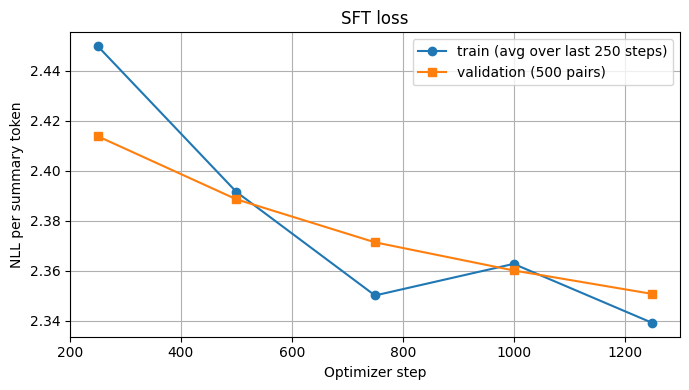

In [26]:
# Figure 1: SFT training and validation loss
plt.figure(figsize=(7, 4))
plt.plot(sft_history["step"], sft_history["train_loss"], marker="o", label="train (avg over last 250 steps)")
plt.plot(sft_history["step"], sft_history["val_loss"], marker="s", label="validation (500 pairs)")
plt.xlabel("Optimizer step"); plt.ylabel("NLL per summary token"); plt.title("SFT loss")
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR / "fig1_sft_loss.png", dpi=150); plt.show()

## 8. Stage 2 — Reward model

Architecture: transformer body of the SFT checkpoint (`model.model`, no LM head) + `nn.Linear(hidden, 1)` applied to the hidden state of the **last real token** (found with `attention_mask`, never with `input_ids != pad`).
Loss: Bradley–Terry, `-log σ(r(x, y_w) - r(x, y_l))`. AdamW lr 1e-5, batch 8 pairs (1 pair × 8 accumulation), 1 epoch. Validation accuracy on the 1,000 validation pairs is logged every 250 optimizer steps.

In [27]:
for _name in ("sft_model", "baseline_model"):
    if _name in globals():
        del globals()[_name]
free_memory()

class RewardModel(nn.Module):
    def __init__(self, sft_checkpoint_dir):
        super().__init__()
        causal_lm = AutoModelForCausalLM.from_pretrained(str(sft_checkpoint_dir), torch_dtype=torch.float32)
        self.backbone = causal_lm.model                 # transformer body, LM head dropped
        self.hidden_size = causal_lm.config.hidden_size
        self.config = causal_lm.config
        self.reward_head = nn.Linear(self.hidden_size, 1)
        del causal_lm

    def forward(self, input_ids, attention_mask):
        hidden = self.backbone(input_ids=input_ids, attention_mask=attention_mask,
                               position_ids=make_position_ids(attention_mask), use_cache=False).last_hidden_state
        # last REAL token, from the mask (left or right padding both work)
        pos = torch.arange(hidden.size(1), device=hidden.device).unsqueeze(0).expand_as(attention_mask)
        last = pos.masked_fill(attention_mask == 0, -1).max(dim=1).values
        h = hidden[torch.arange(hidden.size(0), device=hidden.device), last]
        with torch.autocast(device_type=hidden.device.type, enabled=False):   # keep the head in fp32
            return self.reward_head(h.float()).squeeze(-1)

def load_reward_model():
    rm = RewardModel(SFT_CHECKPOINT_DIR)
    ckpt = torch.load(RM_CHECKPOINT_DIR / "reward_model.pt", map_location="cpu", weights_only=False)
    rm.load_state_dict(ckpt["model_state_dict"])
    return freeze(rm.to(DEVICE))

reward_model = RewardModel(SFT_CHECKPOINT_DIR)
reward_model.backbone.config.use_cache = False
try:
    reward_model.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
except TypeError:
    reward_model.backbone.gradient_checkpointing_enable()
reward_model = reward_model.to(DEVICE)
reward_optimizer = torch.optim.AdamW(reward_model.parameters(), lr=RM_LEARNING_RATE)
print("Reward model ready. Hidden size:", reward_model.hidden_size)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Reward model ready. Hidden size: 576


In [28]:
@torch.no_grad()
def evaluate_reward_model(model, loader):
    was_training = model.training
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for b in loader:
        n = b["pair_count"]
        with autocast_context():
            r = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE)).float()
        chosen, rejected = r[:n], r[n:]
        loss_sum += -F.logsigmoid(chosen - rejected).sum().item()
        correct += int((chosen > rejected).sum().item())
        total += n
    model.train(was_training)
    return {"loss": loss_sum / total, "accuracy": correct / total}

def train_reward_model(model, train_loader, valid_loader, optimizer):
    hist = {"step": [], "train_loss": [], "val_loss": [], "val_accuracy": []}
    run_loss, run_pairs, step = 0.0, 0, 0
    n_micro = len(train_loader)
    optimizer.zero_grad(set_to_none=True)
    model.train()
    start = time.time()
    for micro, b in enumerate(train_loader, start=1):
        n = b["pair_count"]
        with autocast_context():
            r = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE)).float()
        loss = -F.logsigmoid(r[:n] - r[n:]).mean()        # Bradley-Terry
        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite reward loss at micro-step {micro}")
        scaler.scale(loss / RM_GRAD_ACCUM_STEPS).backward()
        run_loss += loss.item() * n
        run_pairs += n
        if micro % RM_GRAD_ACCUM_STEPS == 0 or micro == n_micro:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), RM_MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            step += 1
            if step % RM_LOG_INTERVAL == 0 or micro == n_micro:
                val = evaluate_reward_model(model, valid_loader)
                hist["step"].append(step)
                hist["train_loss"].append(run_loss / run_pairs)
                hist["val_loss"].append(val["loss"])
                hist["val_accuracy"].append(val["accuracy"])
                print(f"Reward step {step:5d} | train loss {run_loss / run_pairs:.4f} | "
                      f"val loss {val['loss']:.4f} | val acc {val['accuracy']:.4f}")
                run_loss, run_pairs = 0.0, 0
    return hist, time.time() - start

rm_history, STAGE_TIME["reward"] = train_reward_model(reward_model, rm_train_loader, rm_valid_loader, reward_optimizer)
rm_metrics = {"loss": rm_history["val_loss"][-1], "accuracy": rm_history["val_accuracy"][-1]}
print(f"Final pairwise accuracy on {len(preference_valid_records)} val pairs: {rm_metrics['accuracy']:.4f}")
print(f"Reward time: {STAGE_TIME['reward'] / 60:.1f} min")

Reward step   250 | train loss 0.6768 | val loss 0.6626 | val acc 0.5990
Reward step   500 | train loss 0.6676 | val loss 0.6626 | val acc 0.6080
Reward step   750 | train loss 0.6459 | val loss 0.6616 | val acc 0.6100
Reward step  1000 | train loss 0.6301 | val loss 0.6631 | val acc 0.6090
Reward step  1250 | train loss 0.6326 | val loss 0.6791 | val acc 0.5950
Reward step  1500 | train loss 0.6291 | val loss 0.6731 | val acc 0.6330
Reward step  1750 | train loss 0.6142 | val loss 0.6515 | val acc 0.6360
Reward step  2000 | train loss 0.6028 | val loss 0.6657 | val acc 0.6410
Reward step  2250 | train loss 0.6040 | val loss 0.6612 | val acc 0.6250
Reward step  2500 | train loss 0.6075 | val loss 0.6476 | val acc 0.6380
Final pairwise accuracy on 1000 val pairs: 0.6380
Reward time: 82.8 min


Reward checkpoint: ['config.json', 'reward_model.pt', 'tokenizer.json', 'tokenizer_config.json']


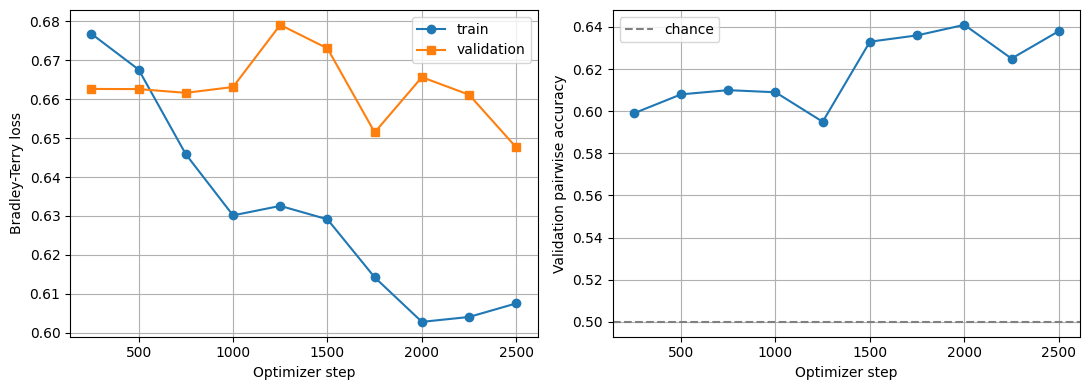

In [29]:
torch.save({"model_state_dict": reward_model.state_dict(), "history": rm_history, "metrics": rm_metrics,
            "seconds": STAGE_TIME["reward"], "seed": SEED}, RM_CHECKPOINT_DIR / "reward_model.pt")
reward_model.config.save_pretrained(RM_CHECKPOINT_DIR)
tokenizer.save_pretrained(RM_CHECKPOINT_DIR)
print("Reward checkpoint:", sorted(p.name for p in RM_CHECKPOINT_DIR.iterdir()))

# Figure 2: reward-model training loss and validation accuracy
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rm_history["step"], rm_history["train_loss"], marker="o", label="train")
ax[0].plot(rm_history["step"], rm_history["val_loss"], marker="s", label="validation")
ax[0].set_xlabel("Optimizer step"); ax[0].set_ylabel("Bradley-Terry loss"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(rm_history["step"], rm_history["val_accuracy"], marker="o")
ax[1].axhline(0.5, ls="--", c="gray", label="chance")
ax[1].set_xlabel("Optimizer step"); ax[1].set_ylabel("Validation pairwise accuracy"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig2_reward_model.png", dpi=150); plt.show()

del reward_optimizer
free_memory()

## 9. Stage 3 — PPO

Exactly the spec: 16 prompts per rollout (sampling at T=1, no top-k/top-p, ≤48 tokens, stop at first EOS), per-token reward `r_t = -β_KL (log π_old − log π_ref) + 1[t=T] r_φ`, **Monte-Carlo returns with γ=1** (`R_t = Σ_k r_{t+k}`, `A_t = R_t − V_old`, normalised over all generated tokens), **K=4 epochs of full-batch updates** on the same rollout (the 16 sequences are processed in two halves whose gradients are added before one `optimizer.step()`), clip ε=0.2, β_KL=0.05, c_V=0.1, c_H=0.01, AdamW 1e-5, clip-norm 1.0, 200 iterations.
Every expectation is a mean over the generated (non-padding) tokens of the whole batch.

In [30]:
PPO_ITERATIONS = 200
PPO_PROMPTS = 16
PPO_EPOCHS = 4
PPO_SPLITS = 2            # memory only: gradients of the two halves are summed before optimizer.step()
PPO_LR = 1e-5
PPO_KL_COEF = 0.05
PPO_CLIP_EPS = 0.2
PPO_VALUE_COEF = 0.1
PPO_ENTROPY_COEF = 0.01
PPO_GAMMA = 1.0
PPO_MAX_GRAD_NORM = 1.0
PPO_LOG_INTERVAL = 10

for _name in ("policy_lm", "reference_lm", "reward_model", "value_head", "ppo_optimizer", "ppo_scaler"):
    if _name in globals():
        del globals()[_name]
free_memory()

policy_lm = AutoModelForCausalLM.from_pretrained(SFT_CHECKPOINT_DIR, torch_dtype=torch.float32)
policy_lm.config.pad_token_id = PAD_ID
policy_lm = enable_gradient_checkpointing(policy_lm).to(DEVICE)
value_head = nn.Linear(policy_lm.config.hidden_size, 1).to(DEVICE)          # new head on the last hidden layer

reference_lm = AutoModelForCausalLM.from_pretrained(SFT_CHECKPOINT_DIR, torch_dtype=torch.float32)
reference_lm.config.pad_token_id = PAD_ID
reference_lm.config.use_cache = False
reference_lm = freeze(reference_lm.to(DEVICE))

reward_model = load_reward_model()                                            # frozen

ppo_optimizer = torch.optim.AdamW(list(policy_lm.parameters()) + list(value_head.parameters()), lr=PPO_LR)
ppo_scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

# Prompts: 3,200 distinct prompts (200 x 16) from the SFT training subset, as token ids.
_order = list(range(len(sft_train_records)))
random.Random(SEED).shuffle(_order)
ppo_prompt_ids = [sft_train_records[i]["prompt_ids"] for i in _order[:PPO_ITERATIONS * PPO_PROMPTS]]
assert len(ppo_prompt_ids) == PPO_ITERATIONS * PPO_PROMPTS

# Correctness check: frozen models
assert all(not p.requires_grad for p in reference_lm.parameters())
assert all(not p.requires_grad for p in reward_model.parameters())
assert any(p.requires_grad for p in policy_lm.parameters()) and any(p.requires_grad for p in value_head.parameters())
print("Frozen-model check passed (reference and reward model have requires_grad=False).")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Frozen-model check passed (reference and reward model have requires_grad=False).


/tmp/ipykernel_50/933311872.py:32: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  ppo_scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))


In [31]:
def policy_forward(model, full_ids, full_mask, prompt_len, resp_ids, with_value=False):
    """Per generated token a_t: log pi(a_t|s_t), entropy of pi(.|s_t), and (optionally) V(s_t).
    Everything is read from the position just BEFORE a_t (the one whose logits predict a_t)."""
    T = resp_ids.shape[1]
    with autocast_context():
        hidden = model.model(input_ids=full_ids, attention_mask=full_mask,
                             position_ids=make_position_ids(full_mask), use_cache=False).last_hidden_state
    h = hidden[:, prompt_len - 1: prompt_len - 1 + T].float()      # only response positions -> small lm_head output
    logits = F.linear(h, model.lm_head.weight)                     # fp32 head: no fp16 rounding noise in log-probs
    lse = torch.logsumexp(logits, dim=-1)
    token_lp = logits.gather(-1, resp_ids.unsqueeze(-1)).squeeze(-1) - lse
    probs = torch.softmax(logits, dim=-1)
    entropy = lse - (probs * logits).sum(-1)
    values = value_head(h.float()).squeeze(-1) if with_value else None
    return token_lp, entropy, values

@torch.no_grad()
def ppo_rollout(prompt_id_lists):
    policy_lm.eval()
    ids, mask = left_pad(prompt_id_lists)
    P = ids.shape[1]
    policy_lm.config.use_cache = True
    gen = policy_lm.generate(input_ids=ids, attention_mask=mask, max_new_tokens=MAX_SUMMARY_TOKENS,
                             do_sample=True, temperature=1.0, top_k=0, top_p=1.0,
                             pad_token_id=PAD_ID, eos_token_id=EOS_ID, use_cache=True)
    policy_lm.config.use_cache = False
    resp = gen[:, P:]
    is_eos = resp.eq(EOS_ID).long()
    resp_mask = ((is_eos.cumsum(1) - is_eos) == 0).long()      # keep tokens up to and including the first EOS
    return {"P": P, "resp": resp, "resp_mask": resp_mask,
            "full_ids": torch.cat([ids, resp], 1),
            "full_mask": torch.cat([mask, resp_mask], 1)}

@torch.no_grad()
def ppo_collect(roll):
    """Stored without gradients: log pi_old, log pi_ref, V_old, reward-model scores."""
    B, T = roll["resp"].shape
    old_lp = torch.zeros(B, T, device=DEVICE); ref_lp = torch.zeros_like(old_lp)
    old_v = torch.zeros_like(old_lp); scores = torch.zeros(B, device=DEVICE)
    policy_lm.eval()
    for sl in chunk_slices(B, PPO_SPLITS):                       # same shapes as in the update -> identical numerics
        args = (roll["full_ids"][sl], roll["full_mask"][sl], roll["P"], roll["resp"][sl])
        old_lp[sl], _, old_v[sl] = policy_forward(policy_lm, *args, with_value=True)
        ref_lp[sl], _, _ = policy_forward(reference_lm, *args)
        with autocast_context():
            scores[sl] = reward_model(roll["full_ids"][sl], roll["full_mask"][sl]).float()
    m = roll["resp_mask"].float()
    old_lp, ref_lp, old_v = old_lp * m, ref_lp * m, old_v * m

    # r_t = -beta (log pi_old - log pi_ref) + 1[t = T] r_phi
    rewards = -PPO_KL_COEF * (old_lp - ref_lp) * m
    last = roll["resp_mask"].sum(1) - 1
    rewards[torch.arange(B, device=DEVICE), last] += scores

    # R_t = sum_{k>=0} gamma^k r_{t+k}  (Monte-Carlo, no GAE);  A_t = R_t - V_old(s_t)
    returns = torch.zeros_like(rewards)
    running = torch.zeros(B, device=DEVICE)
    for t in reversed(range(T)):
        running = rewards[:, t] + PPO_GAMMA * running
        returns[:, t] = running
    returns = returns * m
    adv = (returns - old_v) * m
    valid = adv[m.bool()]
    adv = (adv - valid.mean()) / (valid.std(unbiased=False) + 1e-8) * m
    seq_kl = ((old_lp - ref_lp) * m).sum(1)                      # sum over the summary's tokens
    return {"old_lp": old_lp, "ref_lp": ref_lp, "old_v": old_v, "scores": scores,
            "returns": returns, "adv": adv, "seq_kl": seq_kl}

def ppo_update(roll, st):
    params = list(policy_lm.parameters()) + list(value_head.parameters())
    m_all = roll["resp_mask"].float()
    N = m_all.sum()                                               # all generated tokens in the batch
    B = m_all.shape[0]
    log = {"policy_loss": [], "value_loss": [], "entropy": [], "clip_fraction": [], "max_ratio_dev": []}
    policy_lm.train()
    for epoch in range(PPO_EPOCHS):
        ppo_optimizer.zero_grad(set_to_none=True)
        pg_e = vf_e = en_e = clip_e = 0.0
        dev_e = 0.0
        for sl in chunk_slices(B, PPO_SPLITS):
            new_lp, ent, v = policy_forward(policy_lm, roll["full_ids"][sl], roll["full_mask"][sl],
                                            roll["P"], roll["resp"][sl], with_value=True)
            m = m_all[sl]
            ratio = torch.exp(new_lp - st["old_lp"][sl])
            a = st["adv"][sl]
            surr = torch.minimum(ratio * a, ratio.clamp(1 - PPO_CLIP_EPS, 1 + PPO_CLIP_EPS) * a)
            pg = -(surr * m).sum() / N                            # -L_PPO
            vf = (((v - st["returns"][sl]) ** 2) * m).sum() / N
            en = (ent * m).sum() / N
            loss = pg + PPO_VALUE_COEF * vf - PPO_ENTROPY_COEF * en
            ppo_scaler.scale(loss).backward()                     # halves add up to the full-batch mean
            with torch.no_grad():
                pg_e += pg.item(); vf_e += vf.item(); en_e += en.item()
                clip_e += ((((ratio - 1).abs() > PPO_CLIP_EPS).float()) * m).sum().item() / N.item()
                dev_e = max(dev_e, ((ratio - 1).abs() * m).max().item())
        ppo_scaler.unscale_(ppo_optimizer)
        torch.nn.utils.clip_grad_norm_(params, PPO_MAX_GRAD_NORM)
        ppo_scaler.step(ppo_optimizer)
        ppo_scaler.update()
        for k, val in zip(log, (pg_e, vf_e, en_e, clip_e, dev_e)):
            log[k].append(val)
        if epoch == 0:      # correctness check: first epoch has r_t = 1 and clip fraction 0
            assert dev_e < 2e-2 and clip_e == 0.0, f"epoch-0 ratio deviation {dev_e:.2e}, clip {clip_e}"
    return {"policy_loss": float(np.mean(log["policy_loss"])), "value_loss": float(np.mean(log["value_loss"])),
            "entropy": float(np.mean(log["entropy"])), "clip_fraction": float(np.mean(log["clip_fraction"])),
            "clip_fraction_last_epoch": log["clip_fraction"][-1], "epoch0_max_ratio_dev": log["max_ratio_dev"][0]}

In [32]:
ppo_history = {k: [] for k in ("iteration", "reward", "kl", "length", "clip_fraction", "clip_fraction_last_epoch",
                               "policy_loss", "value_loss", "entropy", "epoch0_max_ratio_dev")}
start = time.time()
for it in range(1, PPO_ITERATIONS + 1):
    batch_prompts = ppo_prompt_ids[(it - 1) * PPO_PROMPTS: it * PPO_PROMPTS]
    roll = ppo_rollout(batch_prompts)
    st = ppo_collect(roll)
    if it == 1:   # correctness check: policy == SFT == reference, so KL must be 0
        assert abs(st["seq_kl"].mean().item()) < 1e-2, f"first-iteration KL = {st['seq_kl'].mean().item():.5f}"
        print("PPO first-iteration check passed: KL to reference =", round(st["seq_kl"].mean().item(), 6))
    upd = ppo_update(roll, st)

    ppo_history["iteration"].append(it)
    ppo_history["reward"].append(st["scores"].mean().item())
    ppo_history["kl"].append(st["seq_kl"].mean().item())
    ppo_history["length"].append(roll["resp_mask"].sum(1).float().mean().item())
    for k in ("clip_fraction", "clip_fraction_last_epoch", "policy_loss", "value_loss", "entropy", "epoch0_max_ratio_dev"):
        ppo_history[k].append(upd[k])
    if it % PPO_LOG_INTERVAL == 0 or it == 1:
        print(f"PPO it {it:3d}/{PPO_ITERATIONS} | r_phi {ppo_history['reward'][-1]:7.3f} | KL {ppo_history['kl'][-1]:7.3f} | "
              f"len {ppo_history['length'][-1]:5.1f} | clip {upd['clip_fraction']:.3f} | "
              f"pg {upd['policy_loss']:.3f} vf {upd['value_loss']:.3f} ent {upd['entropy']:.3f}")
    del roll, st
STAGE_TIME["ppo"] = time.time() - start
print(f"PPO time: {STAGE_TIME['ppo'] / 60:.1f} min | max epoch-0 |r-1| over all iterations: {max(ppo_history['epoch0_max_ratio_dev']):.2e}")

PPO first-iteration check passed: KL to reference = 0.0
PPO it   1/200 | r_phi   5.856 | KL   0.000 | len  33.6 | clip 0.061 | pg -0.040 vf 29.785 ent 2.798
PPO it  10/200 | r_phi   6.695 | KL   8.576 | len  28.2 | clip 0.042 | pg -0.028 vf 3.225 ent 3.699
PPO it  20/200 | r_phi   6.691 | KL  12.407 | len  28.8 | clip 0.011 | pg -0.023 vf 1.922 ent 3.843
PPO it  30/200 | r_phi   7.165 | KL  14.874 | len  29.5 | clip 0.007 | pg -0.015 vf 2.948 ent 3.964
PPO it  40/200 | r_phi   6.560 | KL  22.982 | len  28.1 | clip 0.017 | pg -0.026 vf 1.022 ent 4.194
PPO it  50/200 | r_phi   7.409 | KL  17.570 | len  27.1 | clip 0.018 | pg -0.027 vf 1.150 ent 3.455
PPO it  60/200 | r_phi   6.601 | KL  18.896 | len  32.1 | clip 0.013 | pg -0.024 vf 4.779 ent 3.502
PPO it  70/200 | r_phi   6.820 | KL  19.016 | len  33.1 | clip 0.031 | pg -0.032 vf 0.647 ent 3.615
PPO it  80/200 | r_phi   6.831 | KL  23.767 | len  33.1 | clip 0.019 | pg -0.025 vf 0.902 ent 3.700
PPO it  90/200 | r_phi   7.303 | KL  21.397

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

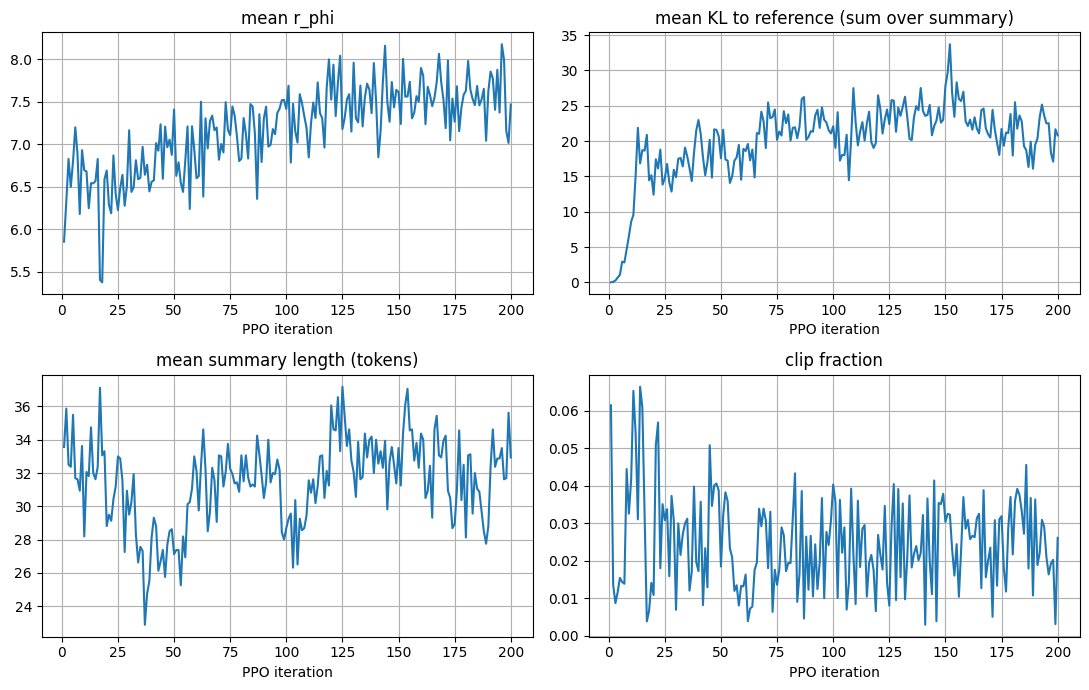

In [33]:
policy_lm.config.use_cache = True
policy_lm.save_pretrained(PPO_CHECKPOINT_DIR, safe_serialization=True)      # policy only, no value head
tokenizer.save_pretrained(PPO_CHECKPOINT_DIR)
torch.save({"history": ppo_history, "seconds": STAGE_TIME["ppo"], "value_head": value_head.state_dict()},
           PPO_CHECKPOINT_DIR / "training_state.pt")
save_json(RESULTS_DIR / "ppo_history.json", ppo_history)

# Figure 3: PPO curves
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for a, key, title in zip(ax.ravel(), ("reward", "kl", "length", "clip_fraction"),
                         ("mean r_phi", "mean KL to reference (sum over summary)", "mean summary length (tokens)", "clip fraction")):
    a.plot(ppo_history["iteration"], ppo_history[key]); a.set_title(title); a.set_xlabel("PPO iteration"); a.grid(True)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig3_ppo.png", dpi=150); plt.show()

for _name in ("policy_lm", "reference_lm", "reward_model", "value_head", "ppo_optimizer"):
    del globals()[_name]
free_memory()

## 10. Stage 4 — DPO

`L = -log σ( β [log π_θ(y_w|x)/π_ref(y_w|x) − log π_θ(y_l|x)/π_ref(y_l|x)] )`, β = 0.1, with `log π(y|x)` = sum of token log-probs over the summary tokens only.
Same 20,000 pairs as the reward model, AdamW lr 2e-6, batch 8 pairs (1 pair × 8 accumulation). Training loss and the implicit-reward accuracy on the 1,000 validation pairs (sign of the expression inside σ) are logged every 250 optimizer steps.
The sequences are the *same token ids* used for the reward model (with the leading space and EOS), not re-tokenised text.

In [34]:
DPO_BETA = 0.1
DPO_LR = 2e-6
DPO_MICRO_BATCH = 1
DPO_GRAD_ACCUM = 8
DPO_MAX_GRAD_NORM = 1.0
DPO_LOG_INTERVAL = 250          # optimizer steps

dpo_policy = AutoModelForCausalLM.from_pretrained(SFT_CHECKPOINT_DIR, torch_dtype=torch.float32)
dpo_policy.config.pad_token_id = PAD_ID
dpo_policy = enable_gradient_checkpointing(dpo_policy).to(DEVICE)

dpo_reference = AutoModelForCausalLM.from_pretrained(SFT_CHECKPOINT_DIR, torch_dtype=torch.float32)
dpo_reference.config.pad_token_id = PAD_ID
dpo_reference.config.use_cache = False
dpo_reference = freeze(dpo_reference.to(DEVICE))
assert all(not p.requires_grad for p in dpo_reference.parameters())
print("DPO reference frozen (requires_grad=False).")

dpo_optimizer = torch.optim.AdamW(dpo_policy.parameters(), lr=DPO_LR)
dpo_scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

dpo_train_loader = DataLoader(preference_train_records, batch_size=DPO_MICRO_BATCH, shuffle=True,
                              collate_fn=collate_reward, generator=torch.Generator().manual_seed(SEED))
dpo_valid_loader = DataLoader(preference_valid_records, batch_size=4, shuffle=False, collate_fn=collate_reward)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

DPO reference frozen (requires_grad=False).


/tmp/ipykernel_50/2239141232.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  dpo_scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))


In [35]:
def dpo_seq_logps(model, batch):
    """log pi(y|x) = sum of token log-probs over the summary tokens only -> (chosen, rejected)."""
    ids = batch["input_ids"].to(DEVICE); am = batch["attention_mask"].to(DEVICE)
    m = summary_mask(am, batch["prompt_lens"]).float()
    seq = (token_logprobs(model, ids, am) * m).sum(1)
    n = batch["pair_count"]
    return seq[:n], seq[n:]

@torch.no_grad()
def reference_val_logps():
    chosen, rejected = [], []
    for b in dpo_valid_loader:
        c, r = dpo_seq_logps(dpo_reference, b)
        chosen.append(c); rejected.append(r)
    return torch.cat(chosen), torch.cat(rejected)

dpo_ref_val = reference_val_logps()          # frozen reference: compute once

@torch.no_grad()
def dpo_validate(policy):
    was_training = policy.training
    policy.eval()
    i, correct, loss_sum = 0, 0, 0.0
    for b in dpo_valid_loader:
        pc, pr = dpo_seq_logps(policy, b)
        n = pc.numel()
        z = DPO_BETA * ((pc - dpo_ref_val[0][i:i + n]) - (pr - dpo_ref_val[1][i:i + n]))
        correct += int((z > 0).sum().item())
        loss_sum += -F.logsigmoid(z).sum().item()
        i += n
    policy.train(was_training)
    return {"accuracy": correct / i, "loss": loss_sum / i}

dpo_history = {"step": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_implicit_acc": []}
dpo_policy.train()
dpo_optimizer.zero_grad(set_to_none=True)
run_loss = run_acc = 0.0
run_n = 0
opt_step = 0
start = time.time()
for micro, b in enumerate(dpo_train_loader, start=1):
    pc, pr = dpo_seq_logps(dpo_policy, b)
    with torch.no_grad():
        rc, rr = dpo_seq_logps(dpo_reference, b)
    z = DPO_BETA * ((pc - rc) - (pr - rr))
    loss = -F.logsigmoid(z).mean()
    if micro == 1:   # correctness check: pi_theta == pi_ref at the first step, so the loss is log 2
        assert abs(loss.item() - math.log(2)) < 1e-3, loss.item()
        print(f"DPO first-step check passed: loss = {loss.item():.4f} (log 2 = {math.log(2):.4f})")
    dpo_scaler.scale(loss / DPO_GRAD_ACCUM).backward()
    run_loss += loss.item(); run_acc += float((z > 0).float().mean()); run_n += 1
    if micro % DPO_GRAD_ACCUM == 0:
        dpo_scaler.unscale_(dpo_optimizer)
        torch.nn.utils.clip_grad_norm_(dpo_policy.parameters(), DPO_MAX_GRAD_NORM)
        dpo_scaler.step(dpo_optimizer)
        dpo_scaler.update()
        dpo_optimizer.zero_grad(set_to_none=True)
        opt_step += 1
        if opt_step % DPO_LOG_INTERVAL == 0:
            val = dpo_validate(dpo_policy)
            dpo_history["step"].append(opt_step)
            dpo_history["train_loss"].append(run_loss / run_n)
            dpo_history["train_acc"].append(run_acc / run_n)
            dpo_history["val_loss"].append(val["loss"])
            dpo_history["val_implicit_acc"].append(val["accuracy"])
            print(f"DPO step {opt_step:5d} | train loss {run_loss / run_n:.4f} | val loss {val['loss']:.4f} | "
                  f"val implicit-reward acc {val['accuracy']:.4f}")
            run_loss = run_acc = 0.0
            run_n = 0
if run_n and (not dpo_history["step"] or dpo_history["step"][-1] != opt_step):   # last partial window (if any)
    val = dpo_validate(dpo_policy)
    for k, v in zip(dpo_history, (opt_step, run_loss / run_n, run_acc / run_n, val["loss"], val["accuracy"])):
        dpo_history[k].append(v)
STAGE_TIME["dpo"] = time.time() - start
print(f"DPO time: {STAGE_TIME['dpo'] / 60:.1f} min | optimizer steps: {opt_step}")

DPO first-step check passed: loss = 0.6931 (log 2 = 0.6931)
DPO step   250 | train loss 0.6749 | val loss 0.6691 | val implicit-reward acc 0.6120
DPO step   500 | train loss 0.6619 | val loss 0.6625 | val implicit-reward acc 0.6150
DPO step   750 | train loss 0.6517 | val loss 0.6583 | val implicit-reward acc 0.6170
DPO step  1000 | train loss 0.6386 | val loss 0.6566 | val implicit-reward acc 0.6090
DPO step  1250 | train loss 0.6388 | val loss 0.6549 | val implicit-reward acc 0.6060
DPO step  1500 | train loss 0.6351 | val loss 0.6569 | val implicit-reward acc 0.6190
DPO step  1750 | train loss 0.6226 | val loss 0.6550 | val implicit-reward acc 0.6170
DPO step  2000 | train loss 0.6244 | val loss 0.6590 | val implicit-reward acc 0.6180
DPO step  2250 | train loss 0.6191 | val loss 0.6583 | val implicit-reward acc 0.6170
DPO step  2500 | train loss 0.6181 | val loss 0.6576 | val implicit-reward acc 0.6120
DPO time: 99.1 min | optimizer steps: 2500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

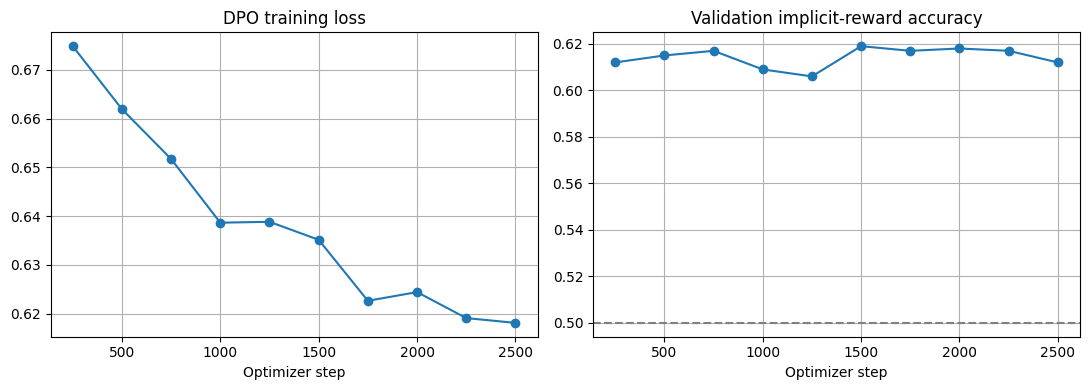

In [36]:
dpo_policy.config.use_cache = True
dpo_policy.save_pretrained(DPO_CHECKPOINT_DIR, safe_serialization=True)
tokenizer.save_pretrained(DPO_CHECKPOINT_DIR)
torch.save({"history": dpo_history, "seconds": STAGE_TIME["dpo"], "beta": DPO_BETA}, DPO_CHECKPOINT_DIR / "training_state.pt")
save_json(RESULTS_DIR / "dpo_history.json", dpo_history)

# Figure 4: DPO training loss and validation implicit-reward accuracy
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(dpo_history["step"], dpo_history["train_loss"], marker="o"); ax[0].set_title("DPO training loss")
ax[1].plot(dpo_history["step"], dpo_history["val_implicit_acc"], marker="o")
ax[1].axhline(0.5, ls="--", c="gray"); ax[1].set_title("Validation implicit-reward accuracy")
for a in ax:
    a.set_xlabel("Optimizer step"); a.grid(True)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "fig4_dpo.png", dpi=150); plt.show()

for _name in ("dpo_policy", "dpo_reference", "dpo_optimizer"):
    del globals()[_name]
free_memory()

## 11. Task 6 — Compare SFT, PPO and DPO on the 300 held-out posts

Summaries are generated greedily (≤ 48 new tokens) and **kept as token ids**. The reward model, the KL and the length are all computed on those exact ids (prompt ids + generated ids, EOS included when generated) — the same format the reward model was trained on. Nothing is re-tokenised from stripped text.
Length = number of generated tokens, EOS included (same convention as the PPO log and Table 1).

In [37]:
def load_policy(path):
    m = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.float32)
    m.config.pad_token_id = PAD_ID
    return freeze(m.to(DEVICE))

eval_models = {"sft": load_policy(SFT_CHECKPOINT_DIR), "ppo": load_policy(PPO_CHECKPOINT_DIR), "dpo": load_policy(DPO_CHECKPOINT_DIR)}
eval_reward_model = load_reward_model()
METHODS = ["sft", "ppo", "dpo"]
eval_prompt_ids = [r["prompt_ids"] for r in eval_records]
print("Loaded:", list(eval_models), "+ reward model (all frozen)")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loaded: ['sft', 'ppo', 'dpo'] + reward model (all frozen)


In [38]:
def cut_at_eos(ids):
    ids = list(ids)
    return ids[:ids.index(EOS_ID) + 1] if EOS_ID in ids else ids

@torch.no_grad()
def greedy_generate_ids(model, prompt_id_lists, batch_size=8):
    out = []
    for s in range(0, len(prompt_id_lists), batch_size):
        ids, mask = left_pad(prompt_id_lists[s:s + batch_size])
        gen = model.generate(input_ids=ids, attention_mask=mask, max_new_tokens=MAX_SUMMARY_TOKENS,
                             do_sample=False, num_beams=1, pad_token_id=PAD_ID, eos_token_id=EOS_ID, use_cache=True)
        out.extend(cut_at_eos(row) for row in gen[:, ids.shape[1]:].tolist())
    return out

@torch.no_grad()
def reward_scores(prompt_id_lists, resp_id_lists, batch_size=16):
    scores = []
    for s in range(0, len(prompt_id_lists), batch_size):
        seqs = [p + r for p, r in zip(prompt_id_lists[s:s + batch_size], resp_id_lists[s:s + batch_size])]
        ids, am = pad_sequences(seqs)
        with autocast_context():
            scores.extend(eval_reward_model(ids.to(DEVICE), am.to(DEVICE)).float().cpu().tolist())
    return scores

@torch.no_grad()
def summary_logps(model, prompt_id_lists, resp_id_lists, batch_size=8):
    """sum_t log pi(y_t | x, y_<t) over the given summary ids."""
    out = []
    for s in range(0, len(prompt_id_lists), batch_size):
        ps, rs = prompt_id_lists[s:s + batch_size], resp_id_lists[s:s + batch_size]
        ids, am = pad_sequences([p + r for p, r in zip(ps, rs)])
        ids, am = ids.to(DEVICE), am.to(DEVICE)
        m = summary_mask(am, torch.tensor([len(p) for p in ps])).float()
        out.extend((token_logprobs(model, ids, am) * m).sum(1).cpu().tolist())
    return out

def to_text(ids):
    return tokenizer.decode([t for t in ids if t != EOS_ID]).strip()

gen_ids = {name: greedy_generate_ids(eval_models[name], eval_prompt_ids) for name in METHODS}
gen_text = {name: [to_text(ids) for ids in gen_ids[name]] for name in METHODS}
rewards = {name: reward_scores(eval_prompt_ids, gen_ids[name]) for name in METHODS}
sft_logp = {name: summary_logps(eval_models["sft"], eval_prompt_ids, gen_ids[name]) for name in METHODS}
own_logp = {name: summary_logps(eval_models[name], eval_prompt_ids, gen_ids[name]) for name in METHODS}
# KL to SFT on the method's own greedy summary: sum_t [log pi_method - log pi_sft]
kl = {name: [a - b for a, b in zip(own_logp[name], sft_logp[name])] for name in METHODS}
print("Generated, scored and KL computed for", METHODS)

Generated, scored and KL computed for ['sft', 'ppo', 'dpo']


In [39]:
from rouge_score import rouge_scorer
rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
references = [r["summary"] for r in eval_records]
rouge_l = {name: [rouge.score(ref, hyp)["rougeL"].fmeasure for ref, hyp in zip(references, gen_text[name])] for name in METHODS}

sft_r = np.array(rewards["sft"])
rows = []
for name in METHODS:
    r = np.array(rewards[name])
    rows.append({
        "Policy": name.upper(),
        "Mean r_phi": float(r.mean()),
        "Win rate vs SFT": None if name == "sft" else float((r > sft_r).mean()),
        "KL to SFT": float(np.mean(kl[name])),
        "Length": float(np.mean([len(x) for x in gen_ids[name]])),
        "ROUGE-L": float(np.mean(rouge_l[name])),
    })
table3 = pd.DataFrame(rows)
display(table3.round(4))
table3.to_csv(RESULTS_DIR / "table3_final_comparison.csv", index=False)

with open(RESULTS_DIR / "eval_summaries.jsonl", "w", encoding="utf-8") as f:
    for i, rec in enumerate(eval_records):
        row = {"id": i, "prompt": rec["prompt"], "reference": rec["summary"]}
        for name in METHODS:
            row.update({f"{name}_summary": gen_text[name][i], f"{name}_reward": rewards[name][i], f"{name}_kl": kl[name][i],
                        f"{name}_length": len(gen_ids[name][i]), f"{name}_rougeL": rouge_l[name][i]})
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
print("Saved results/eval_summaries.jsonl and table3_final_comparison.csv")

,Policy,Mean r_phi,Win rate vs SFT,KL to SFT,Length,ROUGE-L
0,SFT,6.7101,NaN,0.0000,30.41,0.2570
1,PPO,7.7657,0.8133,14.0474,33.07,0.2569
2,DPO,7.1280,0.7400,4.0868,39.45,0.2425


Saved results/eval_summaries.jsonl and table3_final_comparison.csv


In [40]:
# Task 7.1: reward-model accuracy and its mistakes, on the exact token ids used in training.
eval_rm = eval_reward_model
val_prompts = [r["prompt_ids"] for r in preference_valid_records]
val_c = [r["chosen_ids"][len(r["prompt_ids"]):] for r in preference_valid_records]
val_r = [r["rejected_ids"][len(r["prompt_ids"]):] for r in preference_valid_records]
rc = np.array(reward_scores(val_prompts, val_c)); rr = np.array(reward_scores(val_prompts, val_r))
rm_val_accuracy = float((rc > rr).mean())
print(f"Reward-model pairwise accuracy on {len(rc)} validation pairs: {rm_val_accuracy:.4f} "
      f"(training-time value: {rm_metrics['accuracy']:.4f})")

wrong = np.where(rr >= rc)[0]
wrong = wrong[np.argsort(-(rr[wrong] - rc[wrong]))]          # most confidently wrong first
print("Number of mistakes:", len(wrong))
for i in wrong[:3]:
    rec = preference_valid_records[i]
    print("\n--- validation pair", int(i), "---")
    print("POST (tail):", rec["prompt"][-300:].replace("\n", " "))
    print(f"CHOSEN   (r={rc[i]:+.2f}):", rec["chosen"])
    print(f"REJECTED (r={rr[i]:+.2f}):", rec["rejected"])
# Quick descriptive stats to help explain the errors (write the explanation yourself):
len_c = np.array([len(x) for x in val_c]); len_r = np.array([len(x) for x in val_r])
print("\nMean length chosen / rejected:", len_c.mean().round(1), len_r.mean().round(1))
print("Accuracy when chosen is longer:", float((rc > rr)[len_c > len_r].mean()),
      "| when rejected is longer:", float((rc > rr)[len_r > len_c].mean()))

Reward-model pairwise accuracy on 1000 validation pairs: 0.6380 (training-time value: 0.6380)
Number of mistakes: 362

--- validation pair 816 ---
POST (tail): Y church!" or "No, they'll all be on drugs too!"  I feel like this is really the wrong thing to do in response, but I don't know what to do otherwise. If I don't do that, then I just sit on the phone with her for an hour and tell her that I'm here for her. I don't feel like that helps either. TL;DR:
CHOSEN   (r=+4.72): How can I be there for my girlfriend in hard times without physically being there?
REJECTED (r=+8.05): Girlfriend has severe depression and anxiety. I try to be there for her, but she gets panic attacks from seeing the world of drugs and alcohol and leaves me. I don't know what I can do to be more supportive.

--- validation pair 637 ---
POST (tail): time?   -After I'm done with the first 10 minutes of running, how will I be able to regain stamina as quickly as possible (~50 minutes) to run the next 10 minutes, an

In [41]:
# Human evaluation: 30 fixed-seed posts, 3 summaries in random order, model names hidden.
rng = random.Random(SEED)
he_idx = rng.sample(range(len(eval_records)), 30)
sheet, key = [], {}
for post_id in he_idx:
    order = METHODS[:]
    rng.shuffle(order)
    key[str(post_id)] = {label: method for label, method in zip("ABC", order)}
    sheet.append({"post_id": post_id, "post": eval_records[post_id]["prompt"],
                  **{f"summary_{label}": gen_text[method][post_id] for label, method in zip("ABC", order)},
                  "member1_pick": "", "member2_pick": ""})
pd.DataFrame(sheet).to_csv(RESULTS_DIR / "human_eval_sheet.csv", index=False)      # give this to the raters
save_json(RESULTS_DIR / "human_eval_key.json", key)                                # keep this hidden until both have voted
print("Wrote results/human_eval_sheet.csv (fill member1_pick / member2_pick with A, B or C) and human_eval_key.json")

def tally_human_eval(filled_csv=RESULTS_DIR / "human_eval_sheet.csv"):
    """Run after both members filled their picks. Writes results/human_eval.csv and prints Table 4."""
    df = pd.read_csv(filled_csv)
    key = json.load(open(RESULTS_DIR / "human_eval_key.json"))
    for col in ("member1_pick", "member2_pick"):
        df[col.replace("_pick", "_method")] = [key[str(p)][str(c).strip().upper()] for p, c in zip(df["post_id"], df[col])]
    df["agree"] = df["member1_method"] == df["member2_method"]
    df.to_csv(RESULTS_DIR / "human_eval.csv", index=False)
    for who in ("member1", "member2"):
        print(who, df[f"{who}_method"].value_counts().reindex(METHODS, fill_value=0).to_dict())
    print(f"Agreement between members: {int(df['agree'].sum())} / {len(df)}")
    return df

Wrote results/human_eval_sheet.csv (fill member1_pick / member2_pick with A, B or C) and human_eval_key.json


In [42]:
# Draft results/samples.md: 10 posts with the largest reward changes in both directions.
# The "Why" lines are for YOU to fill in after reading the summaries.
delta = {m: np.array(rewards[m]) - np.array(rewards["sft"]) for m in ("ppo", "dpo")}
best = max(delta, key=lambda m: delta[m].max())
picks = []
for m in ("ppo", "dpo"):
    picks += list(np.argsort(-delta[m])[:3]) + list(np.argsort(delta[m])[:2])     # 3 best + 2 worst per method
picks = list(dict.fromkeys(int(i) for i in picks))[:10]
lines = ["# Qualitative samples\n"]
for n, i in enumerate(picks, 1):
    lines += [f"## Sample {n} (eval post {i})", f"**Post (tail):** {eval_records[i]['prompt'][-400:]}", "",
              f"- **Human reference:** {eval_records[i]['summary']}"]
    lines += [f"- **{m.upper()}** (r_phi {rewards[m][i]:+.2f}): {gen_text[m][i]}" for m in METHODS]
    lines += ["- **Better / worse than SFT, and why:** _TODO (write this yourself)_", ""]
(RESULTS_DIR / "samples.md").write_text("\n".join(lines), encoding="utf-8")
print("Wrote results/samples.md with", len(picks), "samples")

Wrote results/samples.md with 9 samples


In [43]:
# Table 2 - training summary (times are wall-clock for each stage on this GPU)
table2 = pd.DataFrame([
    {"Stage": "SFT", "Final train loss": sft_history["train_loss"][-1], "Validation metric": f"val loss {sft_history['val_loss'][-1]:.4f}",
     "Time (min)": STAGE_TIME["sft"] / 60},
    {"Stage": "Reward model", "Final train loss": rm_history["train_loss"][-1], "Validation metric": f"pairwise acc {rm_val_accuracy:.4f}",
     "Time (min)": STAGE_TIME["reward"] / 60},
    {"Stage": "PPO", "Final train loss": float(np.mean(ppo_history["policy_loss"][-10:])), "Validation metric": f"final mean r_phi {np.mean(ppo_history['reward'][-10:]):.3f} (last 10 it.)",
     "Time (min)": STAGE_TIME["ppo"] / 60},
    {"Stage": "DPO", "Final train loss": dpo_history["train_loss"][-1], "Validation metric": f"implicit reward acc {dpo_history['val_implicit_acc'][-1]:.4f}",
     "Time (min)": STAGE_TIME["dpo"] / 60},
])
display(table2.round(4))
table2.to_csv(RESULTS_DIR / "table2_training.csv", index=False)
print("GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

,Stage,Final train loss,Validation metric,Time (min)
0,SFT,2.3391,val loss 2.3506,40.3186
1,Reward model,0.6075,pairwise acc 0.6380,82.7785
2,PPO,-0.0228,final mean r_phi 7.609 (last 10 it.),24.7797
3,DPO,0.6181,implicit reward acc 0.6120,99.0938


GPU: Tesla T4


In [44]:
# Backup results (and optionally checkpoints) to one zip. Do NOT commit checkpoints to GitHub.
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display as _display

INCLUDE_CHECKPOINTS = False
ZIP_PATH = WORK_DIR / "GenAI_Summarization_Project_Backup.zip"
if ZIP_PATH.exists():
    ZIP_PATH.unlink()
roots = [RESULTS_DIR] + ([CHECKPOINT_ROOT] if INCLUDE_CHECKPOINTS else [])
with ZipFile(ZIP_PATH, "w", ZIP_DEFLATED) as z:
    for root in roots:
        for fp in root.rglob("*"):
            if fp.is_file():
                z.write(fp, fp.relative_to(WORK_DIR))
print("Backup:", ZIP_PATH, round(ZIP_PATH.stat().st_size / 1024 ** 2, 1), "MB")
_display(FileLink(str(ZIP_PATH)))

Backup: /kaggle/working/GenAI_Summarization_Project_Backup.zip 0.7 MB


/kaggle/working/GenAI_Summarization_Project_Backup.zip

In [45]:
import shutil, os
from pathlib import Path

# safetensors weights don't compress, so store them uncompressed (fast)
from zipfile import ZipFile, ZIP_STORED
ZIP_CKPT = WORK_DIR / "checkpoints_all.zip"
with ZipFile(ZIP_CKPT, "w", ZIP_STORED) as z:
    for fp in CHECKPOINT_ROOT.rglob("*"):
        if fp.is_file():
            z.write(fp, fp.relative_to(WORK_DIR))
print(ZIP_CKPT, round(ZIP_CKPT.stat().st_size / 1024**3, 2), "GB")

/kaggle/working/checkpoints_all.zip 2.02 GB


In [46]:
sft_history = torch.load(SFT_CHECKPOINT_DIR / "training_state.pt", weights_only=False)["history"]
ppo_state   = torch.load(PPO_CHECKPOINT_DIR / "training_state.pt", weights_only=False)
dpo_state   = torch.load(DPO_CHECKPOINT_DIR / "training_state.pt", weights_only=False)
rm_ckpt     = torch.load(RM_CHECKPOINT_DIR / "reward_model.pt", map_location="cpu", weights_only=False)
ppo_history, dpo_history = ppo_state["history"], dpo_state["history"]
rm_history, rm_metrics   = rm_ckpt["history"], rm_ckpt["metrics"]
del rm_ckpt
STAGE_TIME = {
    "sft":    torch.load(SFT_CHECKPOINT_DIR / "training_state.pt", weights_only=False)["seconds"],
    "reward": torch.load(RM_CHECKPOINT_DIR / "reward_model.pt", map_location="cpu", weights_only=False)["seconds"],
    "ppo":    ppo_state["seconds"],
    "dpo":    dpo_state["seconds"],
}